In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import accuracy_score, confusion_matrix

In [2]:
df = pd.read_csv("../data/StudentsPerformance.csv")

In [3]:
df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   gender                       1000 non-null   str  
 1   race/ethnicity               1000 non-null   str  
 2   parental level of education  1000 non-null   str  
 3   lunch                        1000 non-null   str  
 4   test preparation course      1000 non-null   str  
 5   math score                   1000 non-null   int64
 6   reading score                1000 non-null   int64
 7   writing score                1000 non-null   int64
dtypes: int64(3), str(5)
memory usage: 103.5 KB


In [5]:
df.describe()

,math score,reading score,writing score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


In [6]:
df.isnull().sum()

gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64

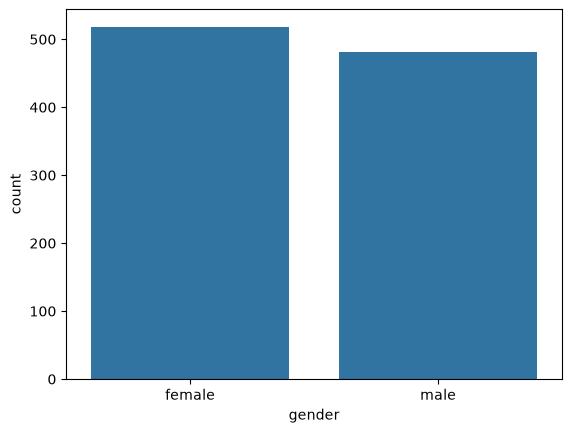

In [7]:
sns.countplot(x="gender", data=df)
plt.show()



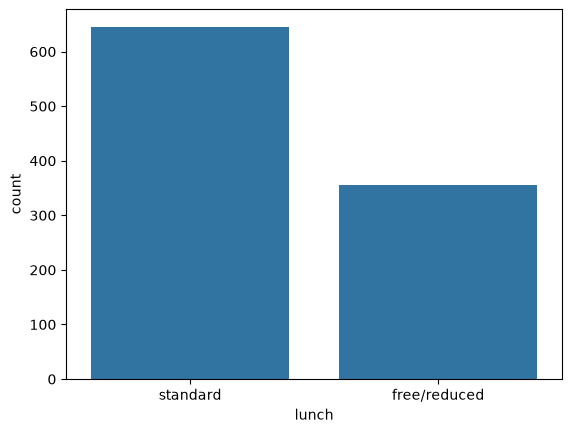

In [8]:
sns.countplot(x="lunch", data=df)
plt.show()


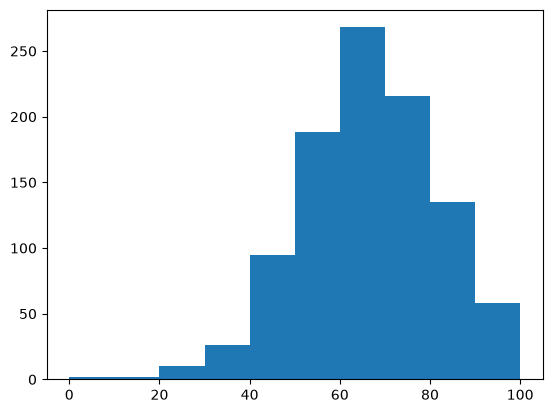

In [9]:
plt.hist(df["math score"])
plt.show()


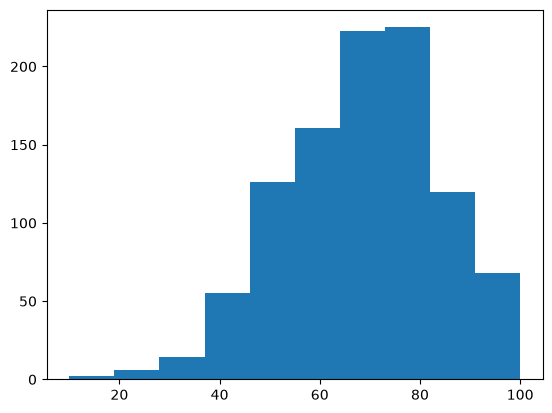

In [12]:
plt.hist(df["writing score"])
plt.show()

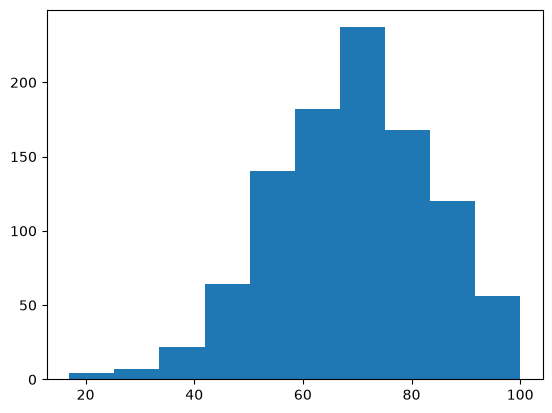

In [13]:
plt.hist(df["reading score"])
plt.show()

In [14]:
df["Performance"] = np.where(df["math score"] >= 60, 1, 0)

In [15]:
df.drop("math score", axis=1, inplace=True)

In [16]:
encoder = LabelEncoder()

for col in df.select_dtypes(include="object"):
    df[col] = encoder.fit_transform(df[col])

In [17]:
X = df.drop("Performance", axis=1)
y = df["Performance"]

In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [20]:
lr = LogisticRegression()

lr.fit(X_train, y_train)

pred1 = lr.predict(X_test)

print(accuracy_score(y_test, pred1))

0.91


C:\Users\User\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [21]:
dt = DecisionTreeClassifier(random_state=42)

dt.fit(X_train, y_train)

pred2 = dt.predict(X_test)

print(accuracy_score(y_test, pred2))

0.86


In [22]:
rf = RandomForestClassifier(random_state=42)

rf.fit(X_train, y_train)

pred3 = rf.predict(X_test)

print(accuracy_score(y_test, pred3))

0.875


In [24]:
import os
import pickle

os.makedirs("../models", exist_ok=True)

with open("../models/model.pkl", "wb") as f:
    pickle.dump(rf, f)

print("Model Saved Successfully!")

Model Saved Successfully!
